In [9]:
import pandas as pd

train = pd.read_csv("../data/fraudTrain.csv")
test = pd.read_csv("../data/fraudTest.csv")

print(len(train), len(test))

1296675 555719


In [8]:
print(train.groupby("is_fraud")["amt"].describe())

              count        mean         std   min       25%      50%      75%  \
is_fraud                                                                        
0         1289169.0   67.667110  154.007971  1.00    9.6100   47.280   82.540   
1            7506.0  531.320092  390.560070  1.06  245.6625  396.505  900.875   

               max  
is_fraud            
0         28948.90  
1          1376.04  


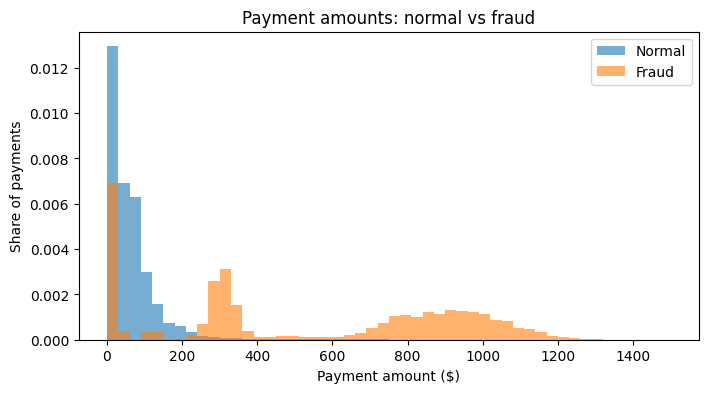

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.hist(train[train["is_fraud"] == 0]["amt"], bins=50, range=(0, 1500), density=True, alpha=0.6, label="Normal")
plt.hist(train[train["is_fraud"] == 1]["amt"], bins=50, range=(0, 1500), density=True, alpha=0.6, label="Fraud")
plt.xlabel("Payment amount ($)")
plt.ylabel("Share of payments")
plt.title("Payment amounts: normal vs fraud")
plt.legend()
plt.show()

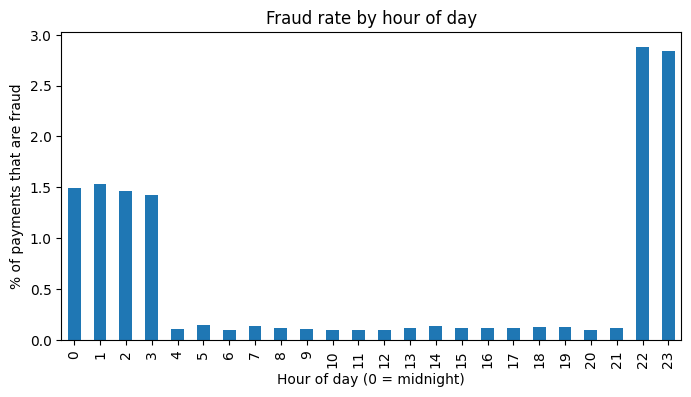

In [10]:
import matplotlib.pyplot as plt

train["hour"] = pd.to_datetime(train["trans_date_trans_time"]).dt.hour
fraud_by_hour = train.groupby("hour")["is_fraud"].mean() * 100

fraud_by_hour.plot(kind="bar", figsize=(8, 4), title="Fraud rate by hour of day")
plt.xlabel("Hour of day (0 = midnight)")
plt.ylabel("% of payments that are fraud")
plt.show()

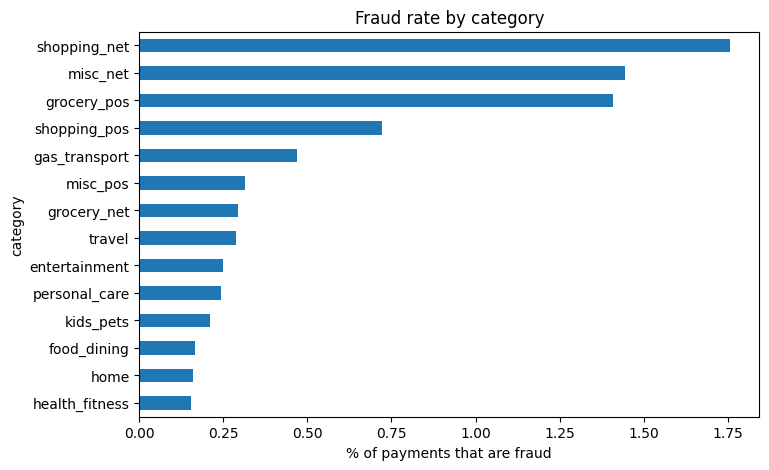

In [16]:
fraud_by_category = train.groupby("category")["is_fraud"].mean().sort_values() * 100 
fraud_by_category.plot(kind = "barh", figsize = (8,5), title = "Fraud rate by category")
plt.xlabel("% of payments that are fraud") 
plt.show()

In [22]:
import numpy as np

def distance_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1,lat2,lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


train ["distance_km"] = distance_km(train["lat"], train["long"], train["merch_lat"], train["merch_long"])
print(train.groupby("is_fraud")["distance_km"].describe())

              count       mean        std       min        25%        50%  \
is_fraud                                                                    
0         1289169.0  76.113756  29.119051  0.022255  55.332701  78.233012   
1            7506.0  76.268330  28.752602  0.738769  55.632890  77.931954   

                75%         max  
is_fraud                         
0         98.504498  152.117173  
1         98.391090  144.522410  
